# Autonomous Astrobiology Multi-Well Microbial Imaging
## In-Situ Image Processing & Document Figures Pipeline
**Document:** `updates/main.tex` / `updates/main.pdf`  
**Organisms Investigated:**
- **Control:** Well 0 ($\mathrm{W}_0$, Sterile Growth Medium)
- **Bacteria 1:** *Shewanella* sp. (Row 1 Well 2, $\mathrm{W}_1$)
- **Bacteria 2:** *Ustilago* sp. (Row 2 Well 2, $\mathrm{W}_3$)

---

### Scope of this Notebook:
This notebook is self-contained and dedicated **strictly** to:
1. **Microplate Motion Registration & Well Tracking:** Tracking cassette displacement, tilt, and scale changes over 52 hours using OpenCV (`cv2.matchTemplate` and adaptive ellipse transformation).
2. **Region of Interest (ROI) Sampling:** Sampling within an inner 90% circular aperture ($0.90\,R$) to capture transmitted liquid light and exclude meniscus reflections/shadows.
3. **Photometric Intensity Measurement & Normalization:** Calculating initial baseline brightness shift ($\alpha$) and live control blank normalization ($I'(t) = I_{\text{adj}}(t) / I_{\text{Control}}(t)$).
4. **Publication Figure Generation:** Producing the exact 5 figures included in the LaTeX report:
   - **Figure 1:** Normalized Mean Intensity over 52 hours
   - **Figure 2:** Spectrophotometer OD600 Growth Curves
   - **Figure 3:** Cross-Modal Growth Comparison (Spectrophotometer vs Image Analysis)
   - **Figure 4:** Well Timelapse Crops across 52 hours
   - **Figure 5:** Well Detection & 90% ROI Geometry across 52 hours


In [1]:
# ==============================================================================
# 1. SETUP, DEPENDENCIES & GLOBAL CONFIGURATION
# ==============================================================================
import os
import glob
from datetime import datetime
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Matplotlib Publication Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#94a3b8'
plt.rcParams['axes.linewidth'] = 1.1

# Project Directories
# Set root workspace directory whether running from repo root or Github folder
WORKSPACE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()).lower() == 'github' else os.getcwd()
DATASET_DIR = os.path.join(WORKSPACE_DIR, 'Dataset')
BACT_DIR = os.path.join(DATASET_DIR, 'Bacteria')
BACT_MARKED_DIR = os.path.join(DATASET_DIR, 'Bacteria_Marked')
UPDATES_DIR = os.path.join(WORKSPACE_DIR, 'updates')
FIG_DIR = os.path.join(UPDATES_DIR, 'figures')
CROPS_DIR = os.path.join(FIG_DIR, 'well_crops')
CROPS_ROI_DIR = os.path.join(FIG_DIR, 'well_crops_roi')

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CROPS_DIR, exist_ok=True)
os.makedirs(CROPS_ROI_DIR, exist_ok=True)

# Centralized Experimental Parameters & Color Palette
SHRINK_FACTOR = 0.90      # 90% ROI radius ratio (0.90 R)
MAX_HOURS = 52.0          # Time analysis truncation window (hours)

COLORS = {
    'control': '#64748b',        # Slate Grey (W0)
    'shewanella_solid': '#7c3aed',# Royal Purple (Spectrophotometer)
    'shewanella_dot': '#6555f7',  # Indigo Purple (Image Analysis)
    'ustilago_solid': '#059669',  # Emerald Green (Spectrophotometer)
    'ustilago_dot': '#17bda7'     # Mint / Teal Green (Image Analysis)
}

print(f"Pipeline initialized. Aperture ROI ratio = {SHRINK_FACTOR:.2f}, Time window = {MAX_HOURS} hours.")
print(f"Colors configured: Shewanella ({COLORS['shewanella_solid']} / {COLORS['shewanella_dot']}), Ustilago ({COLORS['ustilago_solid']} / {COLORS['ustilago_dot']}).")


Pipeline initialized. Aperture ROI ratio = 0.90, Time window = 52.0 hours.
Colors configured: Shewanella (#7c3aed / #6555f7), Ustilago (#059669 / #17bda7).


### 2. Initial Reference Well Detection
From the annotated reference frame in `Dataset/Bacteria_Marked/`, we extract the coordinates of the 4 physical wells:
- **W0:** Control / Live Blank (Row 1 Well 1)
- **W1:** *Shewanella* sp. (Row 1 Well 2)
- **W2:** *Ustilago* sp. Replicate 1 (Row 2 Well 1)
- **W3:** *Ustilago* sp. Replicate 2 (Row 2 Well 2)


In [2]:
# ==============================================================================
# 2. REFERENCE WELL DETECTION
# ==============================================================================
def extract_red_ellipses(image_path, min_perimeter=80):
    """Detects user-marked red circles/ellipses in reference frame using color-ratio thresholding."""
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot load image: {image_path}")
    
    b, g, r = img[:, :, 0].astype(float), img[:, :, 1].astype(float), img[:, :, 2].astype(float)
    red_mask = (r > 130) & (r > 1.3 * g) & (r > 1.3 * b)
    red_mask = (red_mask * 255).astype(np.uint8)
    
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    ellipses = []
    for cnt in contours:
        if cv2.arcLength(cnt, True) > min_perimeter and len(cnt) >= 5:
            ellipses.append(cv2.fitEllipse(cnt))
            
    # Sort row-wise: group by Y (rows ~100px apart), then by X
    ellipses = sorted(ellipses, key=lambda e: (round(e[0][1] / 100) * 100, e[0][0]))
    return ellipses

bact_ref_file = sorted(glob.glob(os.path.join(BACT_MARKED_DIR, '*.jpg')))[0]
bact_ellipses = extract_red_ellipses(bact_ref_file)

print(f"Detected {len(bact_ellipses)} wells in reference frame:")
well_names = ["W0: Control (Blank)", "W1: Shewanella", "W2: Ustilago (Rep 1)", "W3: Ustilago (Rep 2)"]
for i, ((cx, cy), (ax1, ax2), ang) in enumerate(bact_ellipses):
    print(f"  {well_names[i]:24}: Center=({cx:.1f}, {cy:.1f}), Axes=({ax1:.1f}, {ax2:.1f}), Angle={ang:.1f} deg")


Detected 4 wells in reference frame:
  W0: Control (Blank)     : Center=(184.5, 168.0), Axes=(120.6, 125.7), Angle=89.8 deg
  W1: Shewanella          : Center=(344.5, 172.5), Axes=(121.5, 123.7), Angle=90.1 deg
  W2: Ustilago (Rep 1)    : Center=(182.0, 330.0), Axes=(128.6, 128.6), Angle=175.2 deg
  W3: Ustilago (Rep 2)    : Center=(342.5, 330.0), Axes=(127.5, 128.8), Angle=0.3 deg


### 3. OpenCV Plate Motion Tracking & Transmitted Intensity Sampling
During the 52-hour incubation, slight changes in plate position, tilt, and camera distance can occur.
1. **Landmark Tracking:** We track two stable reference landmarks from Frame 0:
   - $L_1$: W0 well rim anchor
   - $L_2$: Central cassette intersection rib
   Tracking is performed via Normalized Cross-Correlation (`cv2.matchTemplate`).
2. **Kinematic Transformation:** From the relative vector between anchors, we compute displacement $(\Delta x, \Delta y)$, rotation $\Delta \theta$, and scale $s$.
3. **Adaptive Ellipse Mapping:** `transform_ellipse_adaptive()` dynamically transforms each well's bounding geometry.
4. **90% Aperture Sampling ($0.90\,R$):** `compute_well_intensity()` creates a binary mask of the central 90% circular core, sampling pure transmitted liquid light and discarding wall reflections, meniscus distortion, and shadows.


In [3]:
# ==============================================================================
# 3. MOTION TRACKING & INTENSITY EXTRACTION PIPELINE
# ==============================================================================
def transform_ellipse_adaptive(el, p_anchor_0, cur_anchor, d_ang_rad, scale):
    """Transforms well ellipse geometry under translation, rotation, and radius scaling."""
    (cx, cy), (ax1, ax2), ang = el
    rel_cx, rel_cy = cx - p_anchor_0[0], cy - p_anchor_0[1]
    
    cos_d, sin_d = np.cos(d_ang_rad), np.sin(d_ang_rad)
    rot_rel_x = scale * (cos_d * rel_cx - sin_d * rel_cy)
    rot_rel_y = scale * (sin_d * rel_cx + cos_d * rel_cy)
    
    new_cx = cur_anchor[0] + rot_rel_x
    new_cy = cur_anchor[1] + rot_rel_y
    new_ax1 = ax1 * scale
    new_ax2 = ax2 * scale
    new_ang = (ang + np.degrees(d_ang_rad)) % 360
    return ((new_cx, new_cy), (new_ax1, new_ax2), new_ang)


def compute_well_intensity(img, ellipse, shrink_factor=0.90):
    """Computes mean pixel intensity inside the shrunken 90% circular aperture."""
    h, w = img.shape[:2]
    (cx, cy), (d1, d2), angle = ellipse
    mask = np.zeros((h, w), dtype=np.uint8)
    shrunk_axes = (int(round(d1 * 0.5 * shrink_factor)), int(round(d2 * 0.5 * shrink_factor)))
    cv2.ellipse(mask, (int(round(cx)), int(round(cy))), shrunk_axes, int(round(angle)), 0, 360, 255, -1)
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if len(img.shape) == 3 else img
    return cv2.mean(gray, mask=mask)[0]


bact_files = sorted(glob.glob(os.path.join(BACT_DIR, '*.jpg')))
print(f"Running adaptive tracking across {len(bact_files)} time-series images...")

# Anchor landmarks from Frame 0
img0 = cv2.imread(bact_files[0])
gray0 = cv2.cvtColor(img0, cv2.COLOR_BGR2GRAY)
p_w0_0 = (bact_ellipses[0][0][0], bact_ellipses[0][0][1])
p_rib_0 = (265.0, 250.0)

t_w0 = gray0[int(p_w0_0[1]-45):int(p_w0_0[1]+45), int(p_w0_0[0]-45):int(p_w0_0[0]+45)]
t_rib = gray0[int(p_rib_0[1]-30):int(p_rib_0[1]+30), int(p_rib_0[0]-30):int(p_rib_0[0]+30)]

v0 = np.array([p_rib_0[0] - p_w0_0[0], p_rib_0[1] - p_w0_0[1]])
L0 = np.linalg.norm(v0)
ang0 = np.arctan2(v0[1], v0[0])

t0_dt = datetime.strptime(os.path.basename(bact_files[0])[6:25], "%Y-%m-%d_%H_%M_%S")
records = []

for idx, fpath in enumerate(bact_files):
    fname = os.path.basename(fpath)
    cur_dt = datetime.strptime(fname[6:25], "%Y-%m-%d_%H_%M_%S")
    elapsed_hours = (cur_dt - t0_dt).total_seconds() / 3600.0
    
    cur_img = cv2.imread(fpath)
    cur_gray = cv2.cvtColor(cur_img, cv2.COLOR_BGR2GRAY)
    
    # 1. Template match anchors
    _, _, _, loc_w0 = cv2.minMaxLoc(cv2.matchTemplate(cur_gray, t_w0, cv2.TM_CCOEFF_NORMED))
    cur_w0 = (loc_w0[0] + 45, loc_w0[1] + 45)
    
    _, _, _, loc_rib = cv2.minMaxLoc(cv2.matchTemplate(cur_gray, t_rib, cv2.TM_CCOEFF_NORMED))
    cur_rib = (loc_rib[0] + 30, loc_rib[1] + 30)
    
    vt = np.array([cur_rib[0] - cur_w0[0], cur_rib[1] - cur_w0[1]])
    scale = np.linalg.norm(vt) / L0
    d_ang_rad = np.arctan2(vt[1], vt[0]) - ang0
    
    row = {
        'Index': idx,
        'Filename': fname,
        'Elapsed_Hours': round(elapsed_hours, 3),
        'Shift_X': round(cur_w0[0] - p_w0_0[0], 2),
        'Shift_Y': round(cur_w0[1] - p_w0_0[1], 2),
        'Rotation_Deg': round(np.degrees(d_ang_rad), 2),
        'Scale_Factor': round(scale, 4)
    }
    
    # 2. Extract intensities for each tracked well
    for w_i, el in enumerate(bact_ellipses):
        adapted = transform_ellipse_adaptive(el, p_w0_0, cur_w0, d_ang_rad, scale)
        (acx, acy), (aax1, aax2), aang = adapted
        intensity = compute_well_intensity(cur_img, adapted, shrink_factor=SHRINK_FACTOR)
        
        row[f"W{w_i}_Intensity"] = round(intensity, 4)
        row[f"W{w_i}_CenterX"] = round(acx, 2)
        row[f"W{w_i}_CenterY"] = round(acy, 2)
        row[f"W{w_i}_AxisA"] = round(aax1, 2)
        row[f"W{w_i}_AxisB"] = round(aax2, 2)
        row[f"W{w_i}_Angle"] = round(aang, 2)
        
    records.append(row)

df_metrics = pd.DataFrame(records)
# Replicate row aliases for downstream convenience
df_metrics['Row1_W2_Intensity'] = df_metrics['W1_Intensity']
df_metrics['Row2_W2_Intensity'] = df_metrics['W3_Intensity']

# Save dataset_image_turbidity_metrics.csv
csv_out = os.path.join(WORKSPACE_DIR, 'dataset_image_turbidity_metrics.csv')
df_metrics.to_csv(csv_out, index=False)
print(f"Tracking complete across {len(df_metrics)} frames! Metrics saved to: {csv_out}")
df_metrics[['Elapsed_Hours', 'Shift_X', 'Shift_Y', 'W0_Intensity', 'W1_Intensity', 'W3_Intensity']].head()


Running adaptive tracking across 288 time-series images...
Tracking complete across 288 frames! Metrics saved to: S:\Sonu\Projects\Astrobiology\dataset_image_turbidity_metrics.csv


### 4. Initial Brightness Alignment & Control Normalization
As detailed in `updates/main.tex`:
1. **Initial Brightness Shift ($\alpha$):**
   Minor lighting differences at $t = 0$ are aligned by scaling each sample by factor $\alpha$:
   $$\alpha = \frac{I_{\text{Control}}(0)}{I(0)}, \qquad I_{\text{adj}}(t) = I(t) \cdot \alpha$$
2. **Normalizing by Control ($I'$):**
   To cancel illumination drift, adjusted brightness is divided by the live Control ($W_0$) at each timepoint:
   $$I'(t) = \frac{I_{\text{adj}}(t)}{I_{\text{Control}}(t)}$$
   The control remains identically at $1.0$. As cells grow and increase turbidity, transmitted light drops below $1.0$.


In [4]:
# ==============================================================================
# 4. BRIGHTNESS SHIFT & NORMALIZATION
# ==============================================================================
df_52 = df_metrics[df_metrics['Elapsed_Hours'] <= MAX_HOURS].copy()
t_cam = df_52['Elapsed_Hours']

# Initial alignment factor alpha
alpha_shew = df_52['W0_Intensity'].iloc[0] / df_52['Row1_W2_Intensity'].iloc[0]
alpha_usti = df_52['W0_Intensity'].iloc[0] / df_52['Row2_W2_Intensity'].iloc[0]

# Adjusted intensities
shew_adj = df_52['Row1_W2_Intensity'] * alpha_shew
usti_adj = df_52['Row2_W2_Intensity'] * alpha_usti

# Normalized intensities (relative to live Control W0)
w0_norm = df_52['W0_Intensity'] / df_52['W0_Intensity']   # Exactly 1.0
shew_norm = shew_adj / df_52['W0_Intensity']
usti_norm = usti_adj / df_52['W0_Intensity']

print(f"Initial shift factors: alpha_Shewanella = {alpha_shew:.4f}, alpha_Ustilago = {alpha_usti:.4f}")
print(f"Hour 0 Normalized Intensities: Control = {w0_norm.iloc[0]:.4f}, Shewanella = {shew_norm.iloc[0]:.4f}, Ustilago = {usti_norm.iloc[0]:.4f}")
print(f"Hour 52 Normalized Intensities: Control = {w0_norm.iloc[-1]:.4f}, Shewanella = {shew_norm.iloc[-1]:.4f}, Ustilago = {usti_norm.iloc[-1]:.4f}")


Initial shift factors: alpha_Shewanella = 0.9604, alpha_Ustilago = 1.0361
Hour 0 Normalized Intensities: Control = 1.0000, Shewanella = 1.0000, Ustilago = 1.0000
Hour 52 Normalized Intensities: Control = 1.0000, Shewanella = 0.8075, Ustilago = 0.7759


### 5. Document Figure 1: Normalized Mean Intensity
Renders **Figure 1** of `updates/main.tex`:
- 52-hour time series
- Control (W0, Slate Grey, dashed), *Shewanella* (Royal Purple), and *Ustilago* (Emerald Green)
- Shaded $\pm 1\,\sigma$ rolling variation envelope
- Saved to `updates/figures/fig1_image_intensity.png` & `.pdf`


[OK] Figure 1 saved to:
  S:\Sonu\Projects\Astrobiology\updates\figures\fig1_image_intensity.png
  S:\Sonu\Projects\Astrobiology\updates\figures\fig1_image_intensity.pdf


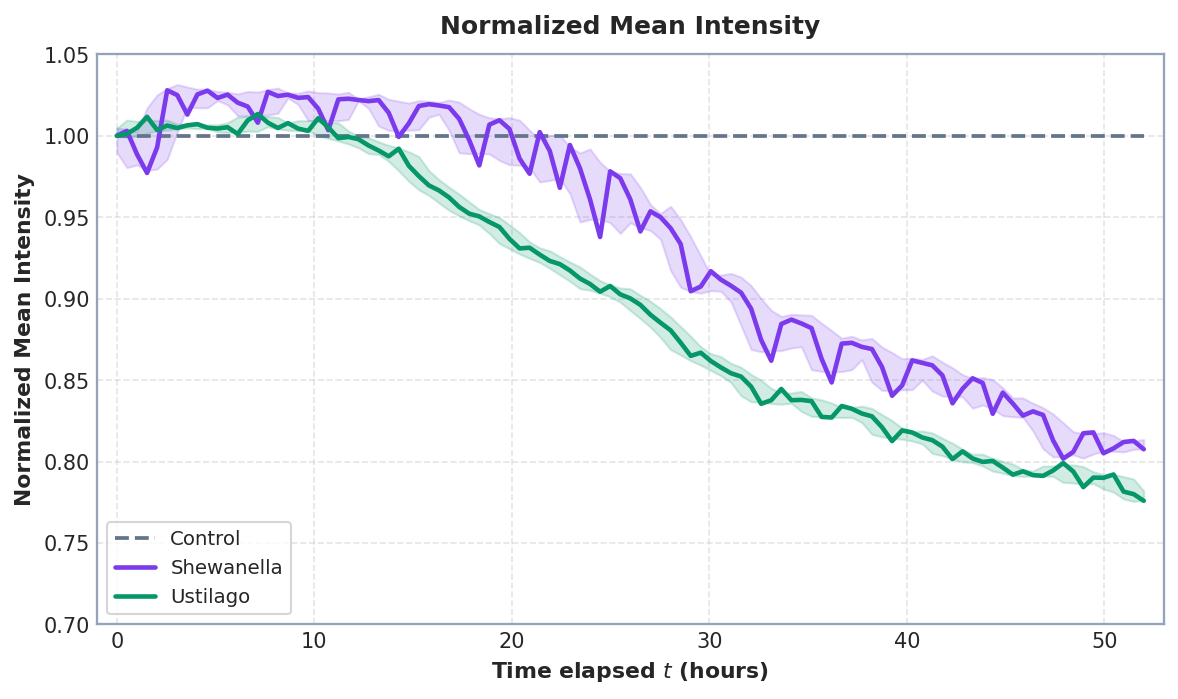

In [5]:
# ==============================================================================
# 5. FIGURE 1: NORMALIZED MEAN INTENSITY
# ==============================================================================
w = 5  # Rolling smoothing window
shew_smooth = shew_norm.rolling(w, center=True, min_periods=1).mean()
shew_std = shew_norm.rolling(w, center=True, min_periods=1).std().fillna(0)
usti_smooth = usti_norm.rolling(w, center=True, min_periods=1).mean()
usti_std = usti_norm.rolling(w, center=True, min_periods=1).std().fillna(0)

fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=300)

# Control
ax.plot(t_cam, w0_norm, color=COLORS['control'], lw=1.8, ls='--', label='Control')

# Shewanella
ax.plot(t_cam, shew_norm, color=COLORS['shewanella_solid'], lw=2.2, label='Shewanella')
ax.fill_between(t_cam, shew_smooth - shew_std, shew_smooth + shew_std,
                color=COLORS['shewanella_solid'], alpha=0.18)

# Ustilago
ax.plot(t_cam, usti_norm, color=COLORS['ustilago_solid'], lw=2.2, label='Ustilago')
ax.fill_between(t_cam, usti_smooth - usti_std, usti_smooth + usti_std,
                color=COLORS['ustilago_solid'], alpha=0.18)

ax.set_title('Normalized Mean Intensity', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Time elapsed $t$ (hours)', fontsize=10.5, fontweight='semibold')
ax.set_ylabel('Normalized Mean Intensity', fontsize=10.5, fontweight='semibold')
ax.set_ylim(0.70, 1.05)
ax.set_xlim(-1.0, 53.0)
ax.grid(True, ls='--', alpha=0.5)
ax.legend(frameon=True, fontsize=9.5, loc='lower left')

plt.tight_layout(pad=1.2)
fig1_png = os.path.join(FIG_DIR, 'fig1_image_intensity.png')
fig1_pdf = os.path.join(FIG_DIR, 'fig1_image_intensity.pdf')
plt.savefig(fig1_png, dpi=300, bbox_inches='tight')
plt.savefig(fig1_pdf, bbox_inches='tight')
plt.show()
print(f"[OK] Figure 1 saved to:\n  {fig1_png}\n  {fig1_pdf}")


### 6. Document Figure 2: Spectrophotometer Growth Curves (OD600)
Renders **Figure 2** of `updates/main.tex`:
- Optical density measured at $630\text{ nm}$ on a laboratory spectrophotometer
- Discrete timepoints from 0 to 51.5 hours connected by linear interpolation lines
- Shaded $\pm 1\,\sigma$ variation bands across replicate wells
- Saved to `updates/figures/fig2_od600_growth.png` & `.pdf`


[OK] Figure 2 saved to:
  S:\Sonu\Projects\Astrobiology\updates\figures\fig2_od600_growth.png
  S:\Sonu\Projects\Astrobiology\updates\figures\fig2_od600_growth.pdf


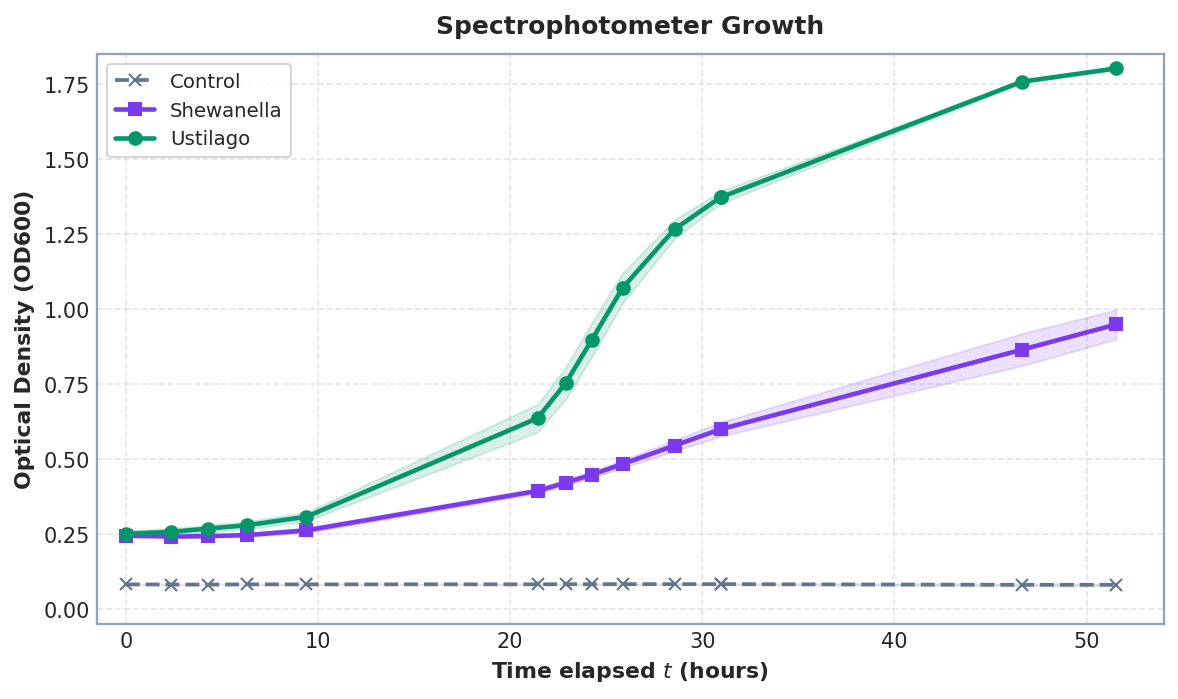

In [6]:
# ==============================================================================
# 6. FIGURE 2: SPECTROPHOTOMETER GROWTH CURVES (OD600)
# ==============================================================================
od_csv_path = os.path.join(WORKSPACE_DIR, 'OD600', 'od600_growth_summary.csv')
df_od = pd.read_csv(od_csv_path)
t_od = df_od['Time_Hours']

fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=300)

# Control
ax.plot(t_od, df_od['Control_Mean'], 'x--', color=COLORS['control'], lw=1.8, ms=6, label='Control')
ax.fill_between(t_od, df_od['Control_Mean'] - df_od['Control_Std'], df_od['Control_Mean'] + df_od['Control_Std'],
                color=COLORS['control'], alpha=0.15)

# Shewanella
ax.plot(t_od, df_od['Shewanella_Mean'], 's-', color=COLORS['shewanella_solid'], lw=2.2, ms=6, label='Shewanella')
ax.fill_between(t_od, df_od['Shewanella_Mean'] - df_od['Shewanella_Std'], df_od['Shewanella_Mean'] + df_od['Shewanella_Std'],
                color=COLORS['shewanella_solid'], alpha=0.15)

# Ustilago
ax.plot(t_od, df_od['Ustilago_Mean'], 'o-', color=COLORS['ustilago_solid'], lw=2.2, ms=6, label='Ustilago')
ax.fill_between(t_od, df_od['Ustilago_Mean'] - df_od['Ustilago_Std'], df_od['Ustilago_Mean'] + df_od['Ustilago_Std'],
                color=COLORS['ustilago_solid'], alpha=0.15)

ax.set_title('Spectrophotometer Growth', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Time elapsed $t$ (hours)', fontsize=10.5, fontweight='semibold')
ax.set_ylabel('Optical Density (OD600)', fontsize=10.5, fontweight='semibold')
ax.set_ylim(-0.05, 1.85)
ax.set_xlim(-1.5, 54.0)
ax.grid(True, ls='--', alpha=0.5)
ax.legend(frameon=True, fontsize=9.5, loc='upper left')

plt.tight_layout(pad=1.2)
fig2_png = os.path.join(FIG_DIR, 'fig2_od600_growth.png')
fig2_pdf = os.path.join(FIG_DIR, 'fig2_od600_growth.pdf')
plt.savefig(fig2_png, dpi=300, bbox_inches='tight')
plt.savefig(fig2_pdf, bbox_inches='tight')
plt.show()
print(f"[OK] Figure 2 saved to:\n  {fig2_png}\n  {fig2_pdf}")


### 7. Document Figure 3: Spectrophotometer vs Image Analysis Comparison
Renders **Figure 3** of `updates/main.tex`:
- Inverting transmission to optical density: $\Delta \text{OD}_{\mathrm{img}}(t) = -\log_{10}(I'(t))$
- Linear calibration transfer functions:
  - *Shewanella*: $\text{OD600} = 6.7402 \cdot \Delta \text{OD}_{\mathrm{img}} + 0.2372$ ($R^2 = 0.965$)
  - *Ustilago*: $\text{OD600} = 14.3959 \cdot \Delta \text{OD}_{\mathrm{img}} + 0.2289$ ($R^2 = 0.984$)
- **Color Scheme:**
  - *Shewanella* Spectrophotometer (Solid): `#7c3aed` with square markers & error bars
  - *Shewanella* Image Analysis (Dashed): `#6555f7` with error bars & shaded variation envelope
  - *Ustilago* Spectrophotometer (Solid): `#059669` with circle markers & error bars
  - *Ustilago* Image Analysis (Dashed): `#17bda7` with error bars & shaded variation envelope
- Saved to `updates/figures/fig3_cross_modal_comparison.png` & `.pdf`


[OK] Figure 3 saved to:
  S:\Sonu\Projects\Astrobiology\updates\figures\fig3_cross_modal_comparison.png
  S:\Sonu\Projects\Astrobiology\updates\figures\fig3_cross_modal_comparison.pdf


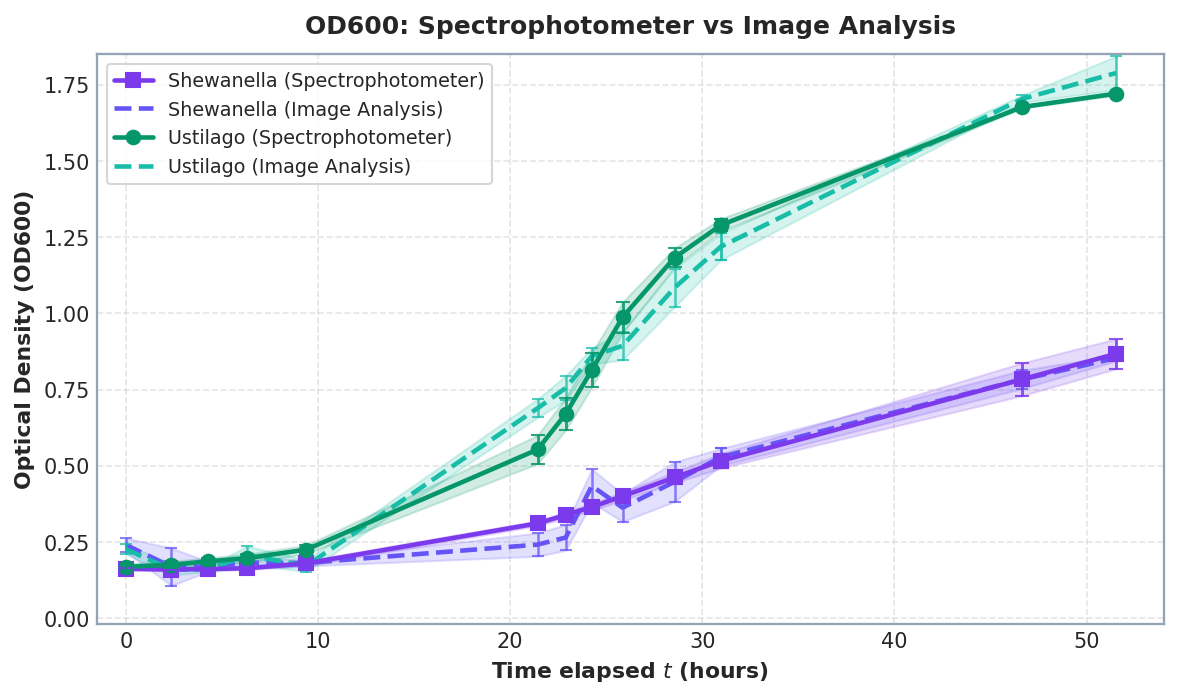

In [7]:
# ==============================================================================
# 7. FIGURE 3: SPECTROPHOTOMETER VS IMAGE ANALYSIS
# ==============================================================================
sync_csv_path = os.path.join(WORKSPACE_DIR, 'cross_modal_od600_vs_image_comparison.csv')
df_sync = pd.read_csv(sync_csv_path)
t_sync = df_sync['Time_OD_h']

# Linear calibration fits
p_s = np.polyfit(df_sync['Cam_OD_Shewanella_LiveW0'], df_sync['OD630_Shewanella_Net'], 1)
p_u = np.polyfit(df_sync['Cam_OD_Ustilago_LiveW0'], df_sync['OD630_Ustilago_Net'], 1)
slope_s, intercept_s = p_s
slope_u, intercept_u = p_u

# Propagated camera standard deviation
w = 5
shew_std = shew_norm.rolling(w, center=True, min_periods=1).std().fillna(0)
usti_std = usti_norm.rolling(w, center=True, min_periods=1).std().fillna(0)
sync_indices = [(df_52['Elapsed_Hours'] - t).abs().idxmin() for t in df_sync['Time_Cam_h']]

cam_std_s = ((slope_s / (np.log(10) * shew_norm.iloc[sync_indices])) * shew_std.iloc[sync_indices]).values
cam_std_u = ((slope_u / (np.log(10) * usti_norm.iloc[sync_indices])) * usti_std.iloc[sync_indices]).values

y_cam_s = df_sync['Cam_OD_Shewanella_LiveW0'] * slope_s + intercept_s
y_cam_u = df_sync['Cam_OD_Ustilago_LiveW0'] * slope_u + intercept_u

fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=300)

# 1. Shewanella Spectrophotometer (Solid + Square Markers)
ax.plot(t_sync, df_sync['OD630_Shewanella_Net'], 's-', color=COLORS['shewanella_solid'],
        lw=2.2, ms=6.5, label='Shewanella (Spectrophotometer)', zorder=6)
ax.fill_between(t_sync, df_sync['OD630_Shewanella_Net'] - df_sync['OD630_Shewanella_Std'],
                df_sync['OD630_Shewanella_Net'] + df_sync['OD630_Shewanella_Std'],
                color=COLORS['shewanella_solid'], alpha=0.18, zorder=3)
ax.errorbar(t_sync, df_sync['OD630_Shewanella_Net'], yerr=df_sync['OD630_Shewanella_Std'],
            fmt='none', ecolor=COLORS['shewanella_solid'], elinewidth=1.4, capsize=3.5, alpha=0.85, zorder=7)

# 2. Shewanella Image Analysis (Dashed + Indigo Purple)
ax.plot(t_sync, y_cam_s, '--', color=COLORS['shewanella_dot'],
        lw=2.2, label='Shewanella (Image Analysis)', zorder=5)
ax.fill_between(t_sync, y_cam_s - cam_std_s, y_cam_s + cam_std_s,
                color=COLORS['shewanella_dot'], alpha=0.18, zorder=2)
ax.errorbar(t_sync, y_cam_s, yerr=cam_std_s,
            fmt='none', ecolor=COLORS['shewanella_dot'], elinewidth=1.2, capsize=3, alpha=0.75, zorder=5)

# 3. Ustilago Spectrophotometer (Solid + Circle Markers)
ax.plot(t_sync, df_sync['OD630_Ustilago_Net'], 'o-', color=COLORS['ustilago_solid'],
        lw=2.2, ms=6.5, label='Ustilago (Spectrophotometer)', zorder=6)
ax.fill_between(t_sync, df_sync['OD630_Ustilago_Net'] - df_sync['OD630_Ustilago_Std'],
                df_sync['OD630_Ustilago_Net'] + df_sync['OD630_Ustilago_Std'],
                color=COLORS['ustilago_solid'], alpha=0.18, zorder=3)
ax.errorbar(t_sync, df_sync['OD630_Ustilago_Net'], yerr=df_sync['OD630_Ustilago_Std'],
            fmt='none', ecolor=COLORS['ustilago_solid'], elinewidth=1.4, capsize=3.5, alpha=0.85, zorder=7)

# 4. Ustilago Image Analysis (Dashed + Mint Green)
ax.plot(t_sync, y_cam_u, '--', color=COLORS['ustilago_dot'],
        lw=2.2, label='Ustilago (Image Analysis)', zorder=5)
ax.fill_between(t_sync, y_cam_u - cam_std_u, y_cam_u + cam_std_u,
                color=COLORS['ustilago_dot'], alpha=0.18, zorder=2)
ax.errorbar(t_sync, y_cam_u, yerr=cam_std_u,
            fmt='none', ecolor=COLORS['ustilago_dot'], elinewidth=1.2, capsize=3, alpha=0.75, zorder=5)

ax.set_title('OD600: Spectrophotometer vs Image Analysis', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Time elapsed $t$ (hours)', fontsize=10.5, fontweight='semibold')
ax.set_ylabel('Optical Density (OD600)', fontsize=10.5, fontweight='semibold')
ax.set_ylim(-0.02, 1.85)
ax.set_xlim(-1.5, 54.0)
ax.grid(True, ls='--', alpha=0.5)
ax.legend(frameon=True, fontsize=9.2, loc='upper left')

plt.tight_layout(pad=1.2)
fig3_png = os.path.join(FIG_DIR, 'fig3_cross_modal_comparison.png')
fig3_pdf = os.path.join(FIG_DIR, 'fig3_cross_modal_comparison.pdf')
plt.savefig(fig3_png, dpi=300, bbox_inches='tight')
plt.savefig(fig3_pdf, bbox_inches='tight')
plt.show()
print(f"[OK] Figure 3 saved to:\n  {fig3_png}\n  {fig3_pdf}")


### 8. Document Figure 4: Well Timelapse Crops Across 52 Hours
Renders **Figure 4** of `updates/main.tex`:
- 144x144 pixel square crops centered on each tracked well at hours 0, 13, 26, 52
- Conditions: Control (W0), *Shewanella* (W1), *Ustilago* (W3)
- Condition-colored square borders matching the growth curves
- Saved to `updates/figures/fig4_well_timelapse.png` & individual crops in `well_crops/`


[OK] Figure 4 saved to:
  S:\Sonu\Projects\Astrobiology\updates\figures\fig4_well_timelapse.png
  S:\Sonu\Projects\Astrobiology\updates\figures\fig4_well_timelapse.pdf


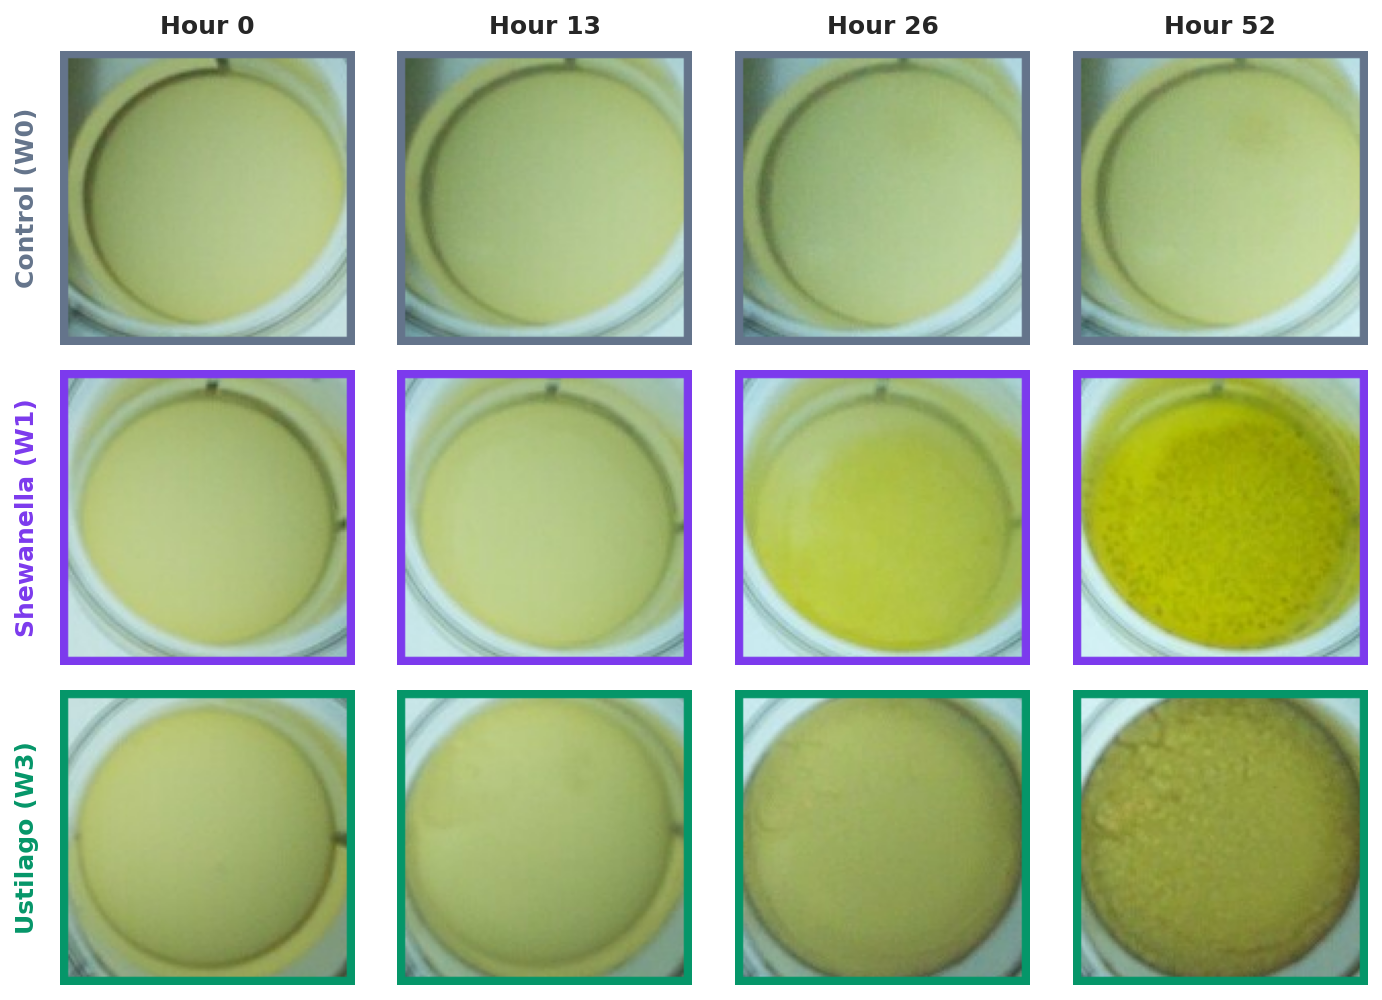

In [8]:
# ==============================================================================
# 8. FIGURE 4: WELL TIMELAPSE CROPS
# ==============================================================================
wells_meta = [
    {'code': 'W0', 'label': 'Control (W0)', 'border_rgb': (100, 116, 139), 'hex': '#64748b'},
    {'code': 'W1', 'label': 'Shewanella (W1)', 'border_rgb': (124, 58, 237), 'hex': '#7c3aed'},
    {'code': 'W3', 'label': 'Ustilago (W3)', 'border_rgb': (5, 150, 105), 'hex': '#059669'}
]
target_hours = [0.0, 13.0, 26.0, 52.0]
time_labels = ['Hour 0', 'Hour 13', 'Hour 26', 'Hour 52']
half_s = 72
bw = 4

fig4_crops = {w['code']: [] for w in wells_meta}

for w_info in wells_meta:
    w_code = w_info['code']
    b_color = w_info['border_rgb']
    for h in target_hours:
        idx = (df_metrics['Elapsed_Hours'] - h).abs().idxmin()
        row = df_metrics.loc[idx]
        img = cv2.imread(os.path.join(BACT_DIR, row['Filename']))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        ix, iy = int(round(row[f"{w_code}_CenterX"])), int(round(row[f"{w_code}_CenterY"]))
        x1, x2 = ix - half_s, ix + half_s
        y1, y2 = iy - half_s, iy + half_s
        
        crop = img_rgb[y1:y2, x1:x2].copy()
        crop[:bw, :] = b_color
        crop[-bw:, :] = b_color
        crop[:, :bw] = b_color
        crop[:, -bw:] = b_color
        fig4_crops[w_code].append(crop)
        
        # Save individual crop
        h_int = int(round(h))
        cv2.imwrite(os.path.join(CROPS_DIR, f"{w_code}_hour_{h_int}.png"), cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))

# Assemble 3x4 Grid
fig, axes = plt.subplots(3, 4, figsize=(9.5, 6.8), dpi=300)
for r, w_info in enumerate(wells_meta):
    w_code = w_info['code']
    for c, h_lbl in enumerate(time_labels):
        ax = axes[r, c]
        ax.imshow(fig4_crops[w_code][c])
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if r == 0:
            ax.set_title(h_lbl, fontsize=12, fontweight='bold', pad=8)
        if c == 0:
            ax.set_ylabel(w_info['label'], fontsize=12, fontweight='bold', color=w_info['hex'], labelpad=10)

plt.tight_layout(pad=1.2)
fig4_png = os.path.join(FIG_DIR, 'fig4_well_timelapse.png')
fig4_pdf = os.path.join(FIG_DIR, 'fig4_well_timelapse.pdf')
plt.savefig(fig4_png, bbox_inches='tight')
plt.savefig(fig4_pdf, bbox_inches='tight')
plt.show()
print(f"[OK] Figure 4 saved to:\n  {fig4_png}\n  {fig4_pdf}")


### 9. Document Figure 5: Well Detection & 90% ROI Geometry Across 52 Hours
Renders **Figure 5** of `updates/main.tex`:
- Outer green ellipse: Total detected well boundary tracked frame-by-frame with OpenCV
- Inner condition-colored circle: 90% aperture radius ($0.90\,R$) matching each condition's growth curve color
- Saved to `updates/figures/fig5_well_timelapse_roi.png` & individual crops in `well_crops_roi/`


[OK] Figure 5 saved to:
  S:\Sonu\Projects\Astrobiology\updates\figures\fig5_well_timelapse_roi.png
  S:\Sonu\Projects\Astrobiology\updates\figures\fig5_well_timelapse_roi.pdf


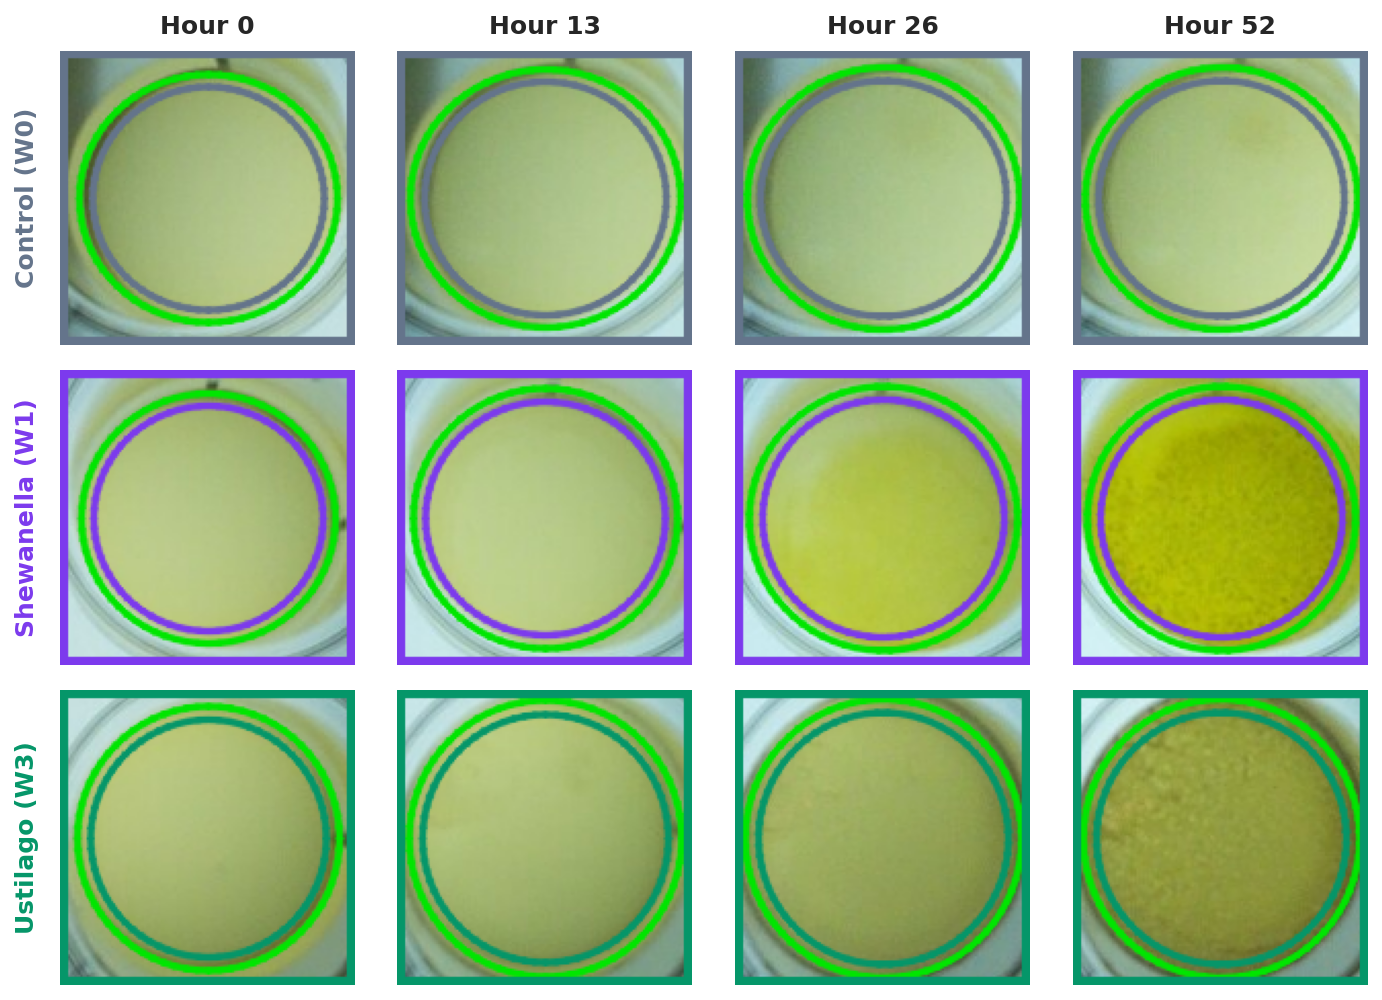

In [9]:
# ==============================================================================
# 9. FIGURE 5: WELL DETECTION & 90% ROI GEOMETRY
# ==============================================================================
fig5_crops = {w['code']: [] for w in wells_meta}

for w_info in wells_meta:
    w_code = w_info['code']
    b_color = w_info['border_rgb']
    for h in target_hours:
        idx = (df_metrics['Elapsed_Hours'] - h).abs().idxmin()
        row = df_metrics.loc[idx]
        img = cv2.imread(os.path.join(BACT_DIR, row['Filename']))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        ix, iy = int(round(row[f"{w_code}_CenterX"])), int(round(row[f"{w_code}_CenterY"]))
        ax_a = row[f"{w_code}_AxisA"]
        ax_b = row[f"{w_code}_AxisB"]
        ang = row[f"{w_code}_Angle"]
        
        x1, x2 = ix - half_s, ix + half_s
        y1, y2 = iy - half_s, iy + half_s
        crop = img_rgb[y1:y2, x1:x2].copy()
        center_pt = (half_s, half_s)
        
        # Outer green tracked boundary
        cv2.ellipse(crop, (center_pt, (int(round(ax_a)), int(round(ax_b))), ang), (0, 230, 0), 2, cv2.LINE_AA)
        
        # Inner 90% ROI circle in species color
        cv2.ellipse(crop, (center_pt, (int(round(ax_a * SHRINK_FACTOR)), int(round(ax_b * SHRINK_FACTOR))), ang),
                    b_color, 2, cv2.LINE_AA)
        
        # Border
        crop[:bw, :] = b_color
        crop[-bw:, :] = b_color
        crop[:, :bw] = b_color
        crop[:, -bw:] = b_color
        fig5_crops[w_code].append(crop)
        
        # Save individual annotated crop
        h_int = int(round(h))
        cv2.imwrite(os.path.join(CROPS_ROI_DIR, f"{w_code}_hour_{h_int}_roi.png"), cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))

# Assemble 3x4 Grid
fig, axes = plt.subplots(3, 4, figsize=(9.5, 6.8), dpi=300)
for r, w_info in enumerate(wells_meta):
    w_code = w_info['code']
    for c, h_lbl in enumerate(time_labels):
        ax = axes[r, c]
        ax.imshow(fig5_crops[w_code][c])
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if r == 0:
            ax.set_title(h_lbl, fontsize=12, fontweight='bold', pad=8)
        if c == 0:
            ax.set_ylabel(w_info['label'], fontsize=12, fontweight='bold', color=w_info['hex'], labelpad=10)

plt.tight_layout(pad=1.2)
fig5_png = os.path.join(FIG_DIR, 'fig5_well_timelapse_roi.png')
fig5_pdf = os.path.join(FIG_DIR, 'fig5_well_timelapse_roi.pdf')
plt.savefig(fig5_png, bbox_inches='tight')
plt.savefig(fig5_pdf, bbox_inches='tight')
plt.show()
print(f"[OK] Figure 5 saved to:\n  {fig5_png}\n  {fig5_pdf}")


### 10. Summary & Document Artifacts Verification
Verifies that all 5 publication figures generated by this pipeline match the requirements of `updates/main.tex`.


In [10]:
# ==============================================================================
# 10. SUMMARY & VERIFICATION
# ==============================================================================
expected_figs = [
    ('Figure 1: Normalized Mean Intensity', 'fig1_image_intensity.png', 'fig1_image_intensity.pdf'),
    ('Figure 2: Spectrophotometer OD600', 'fig2_od600_growth.png', 'fig2_od600_growth.pdf'),
    ('Figure 3: OD600 Cross-Modal Comparison', 'fig3_cross_modal_comparison.png', 'fig3_cross_modal_comparison.pdf'),
    ('Figure 4: Well Timelapse Crops', 'fig4_well_timelapse.png', 'fig4_well_timelapse.pdf'),
    ('Figure 5: Well Detection & 90% ROI Geometry', 'fig5_well_timelapse_roi.png', 'fig5_well_timelapse_roi.pdf')
]

summary_rows = []
for title, png_name, pdf_name in expected_figs:
    png_p = os.path.join(FIG_DIR, png_name)
    pdf_p = os.path.join(FIG_DIR, pdf_name)
    png_size = f"{os.path.getsize(png_p)/1024:.1f} KB" if os.path.exists(png_p) else "MISSING"
    pdf_size = f"{os.path.getsize(pdf_p)/1024:.1f} KB" if os.path.exists(pdf_p) else "MISSING"
    summary_rows.append({'Figure Title': title, 'PNG File': png_name, 'PNG Size': png_size, 'PDF Size': pdf_size})

df_summary = pd.DataFrame(summary_rows)
print("Pipeline Execution Complete! Publication Figures Status:")
try:
    from IPython.display import display
    display(df_summary)
except ImportError:
    print(df_summary.to_string(index=False))


Pipeline Execution Complete! Publication Figures Status:
                                  Figure Title  ...  PDF Size
0          Figure 1: Normalized Mean Intensity  ...   27.2 KB
1            Figure 2: Spectrophotometer OD600  ...   25.0 KB
2       Figure 3: OD600 Cross-Modal Comparison  ...   31.2 KB
3               Figure 4: Well Timelapse Crops  ...  451.8 KB
4  Figure 5: Well Detection & 90% ROI Geometry  ...  513.6 KB

[5 rows x 4 columns]
